# مرحلهٔ ۲: پشت میز DBA

این نوتبوک روایت مرحلهٔ ۲ است. کد واقعی در `src/data_factory/` و همهٔ DDL در `sql/` است؛ اینجا فقط آن‌ها را صدا می‌زنم، نتیجه را نشان می‌دهم و توضیح می‌دهم.

**پیش‌نیاز:** دیتابیس با یک فرمان ساخته شده باشد (`data-factory run`، طبق README). زمان این بارگذاری اولیه جزو بودجهٔ ۱۰ دقیقه‌ای نوتبوک نیست. اتصال فقط از طریق SQLAlchemy است و رمز و پورت از `PGPASSWORD` و `PGPORT` خوانده می‌شوند.

## ۱. آماده‌سازی
یک seed ثابت (برای قاعدهٔ تحویل؛ این نوتبوک تصادف ندارد)، تنظیمات پروژه، و **یک engine** که در آخر نوتبوک بسته می‌شود. هر بخش اتصال خودش را با `with` باز می‌کند و می‌بندد.

In [1]:
import json
import logging
import random
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

from data_factory import benchmark, index_evidence
from data_factory.config import load_config
from data_factory.db import make_engine, server_version
from data_factory import notebook_support as ns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
logging.basicConfig(level=logging.WARNING)

config = load_config("factory.toml")
OLIST = config.olist.load.schema
engine = make_engine(config.database)
print(server_version(engine))

PostgreSQL 18.6 on x86_64-windows, compiled by msvc-19.44.35229, 64-bit


## ۲. دیتابیس با یک فرمان ساخته شده است
تعداد سطرهای هر جدول، مستقیم از دیتابیس. ۳۱۱ در schema `nyc311` و Olist در schema `olist` است؛ هر دو از **همان package** فاز ۱ با مقصد جدید (ایستگاه `load`) آمده‌اند.

In [2]:
COUNT_SQL = text(
    "SELECT table_schema AS schema, table_name AS table, "
    "(xpath('/row/n/text()', query_to_xml(format('SELECT count(*) AS n FROM %I.%I', table_schema, table_name), false, true, '')))[1]::text::bigint AS rows "
    "FROM information_schema.tables WHERE table_schema IN (:a, :b) AND table_type = 'BASE TABLE' ORDER BY 1, 2")
with engine.connect() as connection:
    tables = pd.read_sql_query(COUNT_SQL, connection, params={"a": config.load.schema, "b": OLIST})
tables

,schema,table,rows
0,nyc311,cases,927361
1,nyc311,load_runs,1
2,nyc311,quarantine,0
3,olist,customers,99441
4,olist,load_runs,3
5,olist,notebook_benchmarks,12
6,olist,order_items,112650
7,olist,order_payments,103886
8,olist,order_reviews,99224
9,olist,orders,99441


**گزارش کلید خارجی (خواستهٔ بخش ۱):** manifest اجرای Olist تعداد رکوردهای قرنطینه‌شده و والدهای کامل‌شده را ثبت کرده است. هیچ رکوردی به‌خاطر نقض کلید خارجی کنار گذاشته نشد؛ دو جای واقعی شکست کلید خارجی (دسته‌های بی‌ترجمه و کدهای پستی بی‌موقعیت) با افزودن والد «استنتاج‌شده» حل شد، نه با حذف قید.

In [3]:
manifest = json.loads((config.paths.curated / "olist" / "run_manifest.json").read_text("utf-8"))
counts = manifest["counts"]
fk = pd.DataFrame([{"table": t, "raw": v["raw"], "accepted": v["accepted"], "quarantined": v["quarantined"],
                    "orphan_fk": v["reasons"]["ORPHAN_FOREIGN_KEY"], "parents_completed": v["completed_parents"]}
                   for t, v in counts["tables"].items()])
print("checksums match:", manifest["source"]["all_checksums_match"], "| inferred parents:", manifest["load"]["inferred_parents"])
fk

checksums match: True | inferred parents: {'categories': 2, 'zip_codes': 162}


,table,raw,accepted,quarantined,orphan_fk,parents_completed
0,customers,99441,99441,0,0,"{'zip_code_prefix': {'missing_parents': 157, '..."
1,geolocation_staging,1000163,1000163,0,0,{}
2,order_items,112650,112650,0,0,{}
3,order_payments,103886,103886,0,0,{}
4,order_reviews,99224,99224,0,0,{}
5,orders,99441,99441,0,0,{}
6,product_categories,71,71,0,0,{}
7,products,32951,32951,0,0,"{'category_name': {'missing_parents': 2, 'rows..."
8,sellers,3095,3095,0,0,"{'zip_code_prefix': {'missing_parents': 7, 'ro..."


**فاز ۱ خراب نشد:** اگر manifest فاز ۱ کنار پروژه باشد (`data/work/stage1_manifest.json`)، hash نُه خروجی فعلی با آن مقایسه می‌شود.

In [4]:
check = ns.stage1_hash_check(config.paths.work, config.paths.curated)
check if check is not None else "stage-1 manifest not present on this machine"

,file,stage1,now,identical
0,curated/cases.csv,b551d4dfe275,b551d4dfe275,True
1,curated/quality_report.csv,4bcb6bd266fc,4bcb6bd266fc,True
2,curated/summary_borough_cases.csv,daf90d317c30,daf90d317c30,True
3,curated/summary_borough_median_days.csv,6f90564a234f,6f90564a234f,True
4,curated/summary_borough_rate.csv,7f9d00f53f1a,7f9d00f53f1a,True
5,curated/summary_modzcta_cases.csv,10650eb140bf,10650eb140bf,True
6,curated/summary_modzcta_median_days.csv,e1ab1a8aadba,e1ab1a8aadba,True
7,curated/summary_modzcta_rate.csv,b2ad8ce7869e,b2ad8ce7869e,True
8,quarantine/quarantine.csv,b402508a3e99,b402508a3e99,True


## ۳. طراحی schema: نوع ستون‌ها
نمونهٔ جدول `orders`: شناسه‌ها `uuid` (۱۶ بایت به‌جای ۳۳)، زمان‌ها `timestamp` بدون منطقهٔ زمانی (منبع منطقه ندارد)، تاریخ وعده `date`، و ستون‌های برچسب که خود دیتابیس حساب می‌کند. دلیل هر نوع در `sql/olist/10_tables.sql` و گزارش آمده است.

In [5]:
with engine.connect() as connection:
    orders_types = ns.column_types(connection, OLIST, "orders")
    constraints = pd.read_sql_query(text(
        "SELECT c.contype AS kind, count(*) AS n FROM pg_constraint c JOIN pg_namespace n ON n.oid = c.connamespace "
        "WHERE n.nspname = :schema GROUP BY 1 ORDER BY 1"), connection, params={"schema": OLIST})
display(orders_types)
constraints.replace({"kind": {"c": "CHECK", "f": "FOREIGN KEY", "p": "PRIMARY KEY", "u": "UNIQUE"}})

,column_name,data_type,character_maximum_length
0,order_id,uuid,None
1,customer_id,uuid,None
2,status,text,None
3,purchased_at,timestamp without time zone,None
4,approved_at,timestamp without time zone,None
5,delivered_carrier_at,timestamp without time zone,None
6,delivered_customer_at,timestamp without time zone,None
7,estimated_delivery_date,date,None
8,flag_approved_before_purchase,boolean,None
9,flag_carrier_before_purchase,boolean,None


,kind,n
0,CHECK,24
1,FOREIGN KEY,9
2,n,78
3,PRIMARY KEY,17
4,UNIQUE,1


## ۴. پنج سؤال تیم محصول: نسخهٔ اولیه
روش اندازه‌گیری: ۳ اجرای گرم‌کننده، بعد ۳۰ اجرای زمان‌دار روی یک اتصال؛ زمانِ کامل سمت کلاینت (اجرا + دریافت همهٔ سطرها) و میانه، صدک ۹۵ و بیشینه. **بودجه: صدک ۹۵ زیر ۲۰۰ میلی‌ثانیه.** پارامترها (کل تاریخچه) bind می‌شوند، نه چسبانده.

In [6]:
with engine.connect() as connection:
    ns.use_schema(connection, OLIST)
    baseline = benchmark.run_dashboard(connection, config.dashboard, "baseline", "baseline")
ns.timings_table(baseline)

,query,median_ms,p95_ms,max_ms,rows,server_ms,within_budget
0,q1_sales_by_month_category,1369.52,1411.67,1425.81,1282,953.81,False
1,q2_late_delivery_by_state_month,386.59,416.49,416.79,556,419.78,False
2,q3_delay_vs_review_score,479.19,526.92,531.34,8,433.78,False
3,q4_top_sellers,915.86,951.35,1030.70,20,1078.38,False
4,q5_payments_by_installments,1057.06,1094.89,1095.10,8,715.98,False


**خواندن پلن Q1 (اولیه):** گران‌ترین بخش، مرتب‌سازی ۱۱۲ هزار سطر برای `count(DISTINCT)` است که روی دیسک می‌ریزد (`sort_disk_kb`)؛ همهٔ جدول‌ها با Seq Scan خوانده می‌شوند چون کل تاریخچه لازم است. تخمین و واقعیت سطرها نزدیک‌اند، پس مشکل آمار نیست، حجم کار است.

In [7]:
ns.plan_table(baseline[0])

,node,relation,index,estimated_rows,actual_rows,total_ms,sort_disk_kb
0,Aggregate (Sorted),,,111261,1282.0,931.08,0
1,Sort,,,111261,112101.0,878.11,5544
2,Hash Join,,,111261,112101.0,344.74,0
3,Hash Join,,,111261,112101.0,264.56,0
4,Hash Join,,,111261,112101.0,185.84,0
5,Hash,,,32951,32951.0,16.48,0
6,Hash,,,73,73.0,0.10,0
7,Seq Scan,product_categories,,73,73.0,0.06,0


## ۵. تلاش‌های بدون پیش‌محاسبه: بازنویسی و View
**بازنویسی Q1:** اول برای هر (سفارش، دسته) یک سطر می‌سازم، بعد جمع می‌زنم؛ `count(*)` جای `count(DISTINCT)` را می‌گیرد. **View:** همان محاسبه پشت `sales_monthly_live` (در هر بار خواندن دوباره حساب می‌شود). هر دو نتیجه‌ای دقیقاً برابر Q1 اصلی می‌دهند (تست `test_rewrite_and_view_return_the_original_q1`).

In [8]:
with engine.connect() as connection:
    ns.use_schema(connection, OLIST)
    rewrite = benchmark.run_dashboard(connection, config.dashboard, "rewrite", "rewrite")
    view = benchmark.run_dashboard(connection, config.dashboard, "view", "view")
ns.timings_table(rewrite + view)

,query,median_ms,p95_ms,max_ms,rows,server_ms,within_budget
0,q1_sales_by_month_category_rewrite,1276.67,1323.36,1387.81,1282,632.41,False
1,q1_sales_by_month_category_view,615.44,652.51,733.82,1282,360.31,False


In [9]:
ns.plan_table(rewrite[0])

,node,relation,index,estimated_rows,actual_rows,total_ms,sort_disk_kb
0,Sort,,,11126,1282.0,615.39,0
1,Aggregate (Hashed),,,11126,1282.0,610.37,0
2,Aggregate (Sorted),,,111261,99002.0,556.55,0
3,Sort,,,111261,112101.0,435.60,5544
4,Hash Join,,,111261,112101.0,326.12,0


**چرا Index اینجا کمکی نمی‌کند (کوئری بخش ۵ صورت مسئله):** سؤال «همهٔ ماه‌ها × همهٔ دسته‌ها» است؛ هر سطر `order_items` در جواب سهم دارد. Index برای پیدا کردن *بخش کوچکی* از سطرها است؛ وقتی همه لازم‌اند، Seq Scan ارزان‌ترین راه است و پلن هم همین را نشان می‌دهد (Seq Scan روی هر چهار جدول، با تخمین سطر برابر کل جدول). پس باید **کار را از زمان پرسیدن به زمان بارگذاری منتقل کرد**: جدول snapshot ماهانه.

## ۶. Snapshot ماهانه: پیش‌محاسبه با Procedure
`refresh_month(p_month)` برای هر ماه پنج جدول کوچک (`snap_*`) می‌سازد؛ همهٔ مقادیر جمع‌پذیرند، پس هر بازهٔ چندماهه جمع چند سطر است. کوئری‌های داشبورد روی این جدول‌ها اجرا می‌شوند.

In [10]:
with engine.connect() as connection:
    ns.use_schema(connection, OLIST)
    snapshot = benchmark.run_dashboard(connection, config.dashboard, "snapshot", "snapshot")
ns.timings_table(snapshot)

,query,median_ms,p95_ms,max_ms,rows,server_ms,within_budget
0,q1_sales_by_month_category_snapshot,1.74,3.25,3.83,1282,2.00,True
1,q2_late_delivery_by_state_month_snapshot,1.01,1.19,1.64,556,0.64,True
2,q3_delay_vs_review_score_snapshot,0.18,0.35,0.40,8,0.07,True
3,q4_top_sellers_snapshot,7.58,12.91,13.19,20,9.55,True
4,q5_payments_by_installments_snapshot,0.30,0.49,0.57,8,0.08,True


**پلن قبل و بعد برای هر پنج کوئری.** قبل: Seq Scan و Hash Join روی ده‌ها هزار سطر. بعد: خواندن چند صد تا چند هزار سطر از `snap_*`. نتیجه‌ها یکسان‌اند (تست `test_snapshot_queries_return_the_live_results`)؛ تنها تفاوت Q5 این است که میانه حذف شد، چون میانه بین ماه‌ها جمع‌پذیر نیست.

In [11]:
for before, after in zip(baseline, snapshot):
    print("=" * 30, before.query, f"p95 {before.p95_ms} ms -> {after.p95_ms} ms")
    display(ns.plan_table(before, max_depth=3))
    display(ns.plan_table(after, max_depth=3))

============================== q1_sales_by_month_category p95 1411.67 ms -> 3.25 ms


,node,relation,index,estimated_rows,actual_rows,total_ms,sort_disk_kb
0,Aggregate (Sorted),,,111261,1282.0,931.08,0
1,Sort,,,111261,112101.0,878.11,5544
2,Hash Join,,,111261,112101.0,344.74,0
3,Hash Join,,,111261,112101.0,264.56,0
4,Hash,,,73,73.0,0.10,0


,node,relation,index,estimated_rows,actual_rows,total_ms,sort_disk_kb
0,Sort,,,128,1282.0,1.97,0
1,Aggregate (Hashed),,,128,1282.0,0.67,0
2,Seq Scan,snap_sales,,1282,1282.0,0.08,0


============================== q2_late_delivery_by_state_month p95 416.49 ms -> 1.19 ms


,node,relation,index,estimated_rows,actual_rows,total_ms,sort_disk_kb
0,Aggregate (Sorted),,,96292,556.0,401.18,0
1,Sort,,,96292,96476.0,361.74,2840
2,Hash Join,,,96292,96476.0,155.58,0
3,Seq Scan,orders,,96292,96476.0,28.72,0
4,Hash,,,99441,99441.0,46.14,0


...

,node,relation,index,estimated_rows,actual_rows,total_ms,sort_disk_kb
0,Sort,,,20,20.0,1023.59,0
1,Aggregate (Hashed),,,87854,99542.0,391.62,0
2,Hash Join,,,111261,112101.0,151.93,0
3,Seq Scan,order_items,,112650,112650.0,13.61,0
4,Hash,,,98215,98207.0,64.50,0
5,Aggregate (Hashed),,,20,20.0,1023.55,0
6,Hash Join,,,8785,18908.0,992.74,0
7,Hash Join,,,8785,18908.0,914.42,0
8,Hash,,,99441,99441.0,61.39,0


,node,relation,index,estimated_rows,actual_rows,total_ms,sort_disk_kb
0,Limit,,,20,20.0,9.52,0
1,Sort,,,3053,20.0,9.52,0
2,Aggregate (Hashed),,,3053,3053.0,8.77,0
3,Seq Scan,snap_sellers,,16308,16308.0,0.90,0


============================== q5_payments_by_installments p95 1094.89 ms -> 0.49 ms


,node,relation,index,estimated_rows,actual_rows,total_ms,sort_disk_kb
0,Incremental Sort,,,110,8.0,697.44,0
1,WindowAgg,,,110,8.0,697.41,0
2,Aggregate (Sorted),,,110,8.0,697.32,0
3,Sort,,,90649,102565.0,574.33,3320


,node,relation,index,estimated_rows,actual_rows,total_ms,sort_disk_kb
0,Sort,,,17,8.0,0.06,0
1,WindowAgg,,,17,8.0,0.06,0
2,Aggregate (Hashed),,,17,8.0,0.05,0
3,Seq Scan,snap_payments,,170,170.0,0.01,0


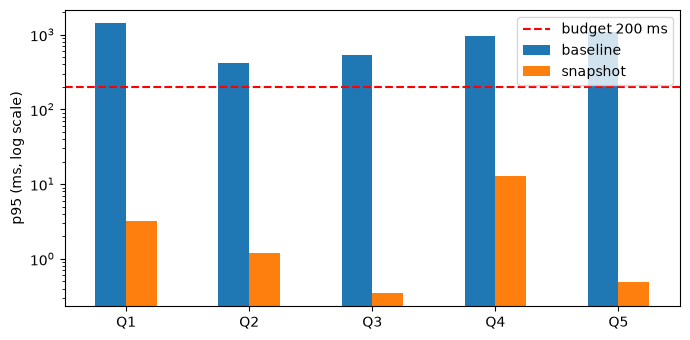

,baseline,snapshot
Q1,1411.67,3.25
Q2,416.49,1.19
Q3,526.92,0.35
Q4,951.35,12.91
Q5,1094.89,0.49


In [12]:
summary = pd.DataFrame({"baseline": [t.p95_ms for t in baseline], "snapshot": [t.p95_ms for t in snapshot]},
                       index=[t.query[:2].upper() for t in baseline])
ax = summary.plot.bar(logy=True, figsize=(7, 3.5), rot=0)
ax.axhline(config.dashboard.budget_ms, color="red", linestyle="--", label="budget 200 ms")
ax.set_ylabel("p95 (ms, log scale)")
ax.legend()
plt.tight_layout()
plt.show()
summary

**ادعای نمودار:** هر پنج کوئری در نسخهٔ اولیه بالای خط قرمز و در نسخهٔ snapshot چند مرتبهٔ بزرگی زیر آن‌اند. **View یا snapshot برای داشبورد؟** View (بخش ۵) همیشه تازه است ولی صدها میلی‌ثانیه طول می‌کشد؛ snapshot چند میلی‌ثانیه است ولی تا اجرای بعدی `refresh_month` کهنه می‌ماند و چند صد کیلوبایت جا و یک Procedure برای نگهداری می‌خواهد. برای داشبورد snapshot را انتخاب می‌کنم: سفارش‌های Olist تاریخی‌اند و تازگی لحظه‌ای ارزشی ندارد.

## ۷. هزینهٔ پنهان Index
همهٔ آزمایش‌ها در تراکنشی اجرا می‌شوند که آخرش rollback می‌شود؛ دیتابیس دست نمی‌خورد. برای هر Index نامزد: پلن و زمان `refresh_month` بدون آن و با آن.

In [13]:
month = date(2018, 1, 1)
candidates = index_evidence.with_and_without(engine, OLIST, month)
pd.DataFrame([{"index": name, "used_by_planner": r["used_by_planner"], "kb": r["with"]["bytes"] // 1024,
               "month_filter_ms_without": r["without"]["plan"]["ms"], "month_filter_ms_with": r["with"]["plan"]["ms"],
               "refresh_ms_without": r["without"]["refresh_ms"], "refresh_ms_with": r["with"]["refresh_ms"],
               "plan_without": " > ".join(r["without"]["plan"]["nodes"]), "plan_with": " > ".join(r["with"]["plan"]["nodes"])}
              for name, r in candidates.items()])

,index,used_by_planner,kb,month_filter_ms_without,month_filter_ms_with,refresh_ms_without,refresh_ms_with,plan_without,plan_with
0,orders_purchased_at_idx,True,2192,7.17,2.02,810.8,749.3,Aggregate > Seq Scan,Aggregate > Index Only Scan using orders_purch...
1,order_reviews_order_id_idx,False,3064,44.55,39.95,732.0,762.2,Aggregate > Hash Join > Hash > Bitmap Heap Sca...,Aggregate > Hash Join > Hash > Bitmap Heap Sca...


`orders_purchased_at_idx` را پلنر استفاده می‌کند: خواندن سفارش‌های یک ماه از Seq Scan به Index Scan می‌رود و زمان همین بخش (`month_filter_ms`) کم می‌شود؛ پس نگهش داشتم. اما روی زمان کل `refresh_month` اثرش در حد نوسان است، چون بیشتر آن زمان صرف join با کل `order_items` و `products` می‌شود، نه پیدا کردن سفارش‌های ماه. `order_reviews_order_id_idx` را ساختم ولی پلن با و بی آن یکی است (یک ماه هنوز هزاران نظر می‌خواهد و Hash Join روی Seq Scan ارزان‌تر است)؛ **حذفش کردم**.

In [14]:
sizes = pd.DataFrame(index_evidence.sizes(engine, OLIST))
by_table = sizes.groupby("table_name").agg(indexes=("index", "count"), index_kb=("index_bytes", lambda b: b.sum() // 1024),
                                           table_kb=("table_bytes", lambda b: b.max() // 1024))
by_table["index_to_table"] = (by_table["index_kb"] / by_table["table_kb"]).round(2)
by_table.sort_values("index_kb", ascending=False).head(8)

,indexes,index_kb,table_kb,index_to_table
table_name,,,,
orders,3,10712,11520,0.93
order_reviews,1,6008,11648,0.52
order_payments,1,5280,7232,0.73
order_items,1,4488,12160,0.37
customers,1,4232,8704,0.49
products,1,1240,2776,0.45
snap_sellers,1,928,5008,0.19
zip_codes,1,440,1480,0.30


In [15]:
insert_ms = index_evidence.insert_cost(engine, OLIST)
pd.Series(insert_ms, name="insert all orders (ms)")

no_index        151.1
primary_key     571.5
all_indexes    1745.2
Name: insert all orders (ms), dtype: float64

**جمع‌بندی Index:** در `orders` حجم Indexها تقریباً هم‌اندازهٔ خود جدول است و درج انبوه با همهٔ Indexها چند برابر کندتر از بدون Index است. فقط Indexی ماند که پلن نشان داد استفاده می‌شود.

## ۸. Procedure و Function
**Procedure** با `CALL` اجرا می‌شود، مقدار برنمی‌گرداند و داخل `SELECT` قابل استفاده نیست؛ کارش تغییر داده است (پاک کردن و ساختن دوبارهٔ یک ماه). **Function** `delay_band` مقدار برمی‌گرداند و داخل `SELECT` و `GROUP BY` به کار می‌رود (در Q3 و داخل خود Procedure). Procedure را دو بار برای یک ماه صدا می‌زنم: تعداد سطرها نباید عوض شود.

In [16]:
COUNTS = text("SELECT (SELECT count(*) FROM snap_sales) AS sales, (SELECT count(*) FROM snap_sellers) AS sellers, "
              "(SELECT count(*) FROM snap_payments) AS payments")
with engine.connect() as connection:
    ns.use_schema(connection, OLIST)
    before = connection.execute(COUNTS).one()
    for _ in range(2):
        connection.execute(text("CALL refresh_month(:m)"), {"m": month})
    connection.commit()
    after = connection.execute(COUNTS).one()
    bands = pd.read_sql_query(text("SELECT d AS delay_days, delay_band(d) AS band FROM unnest(CAST(:days AS int[])) AS d"),
                              connection, params={"days": [-20, -8, -1, 0, 2, 5, 10, 30]})
print("before:", tuple(before), "after two CALLs:", tuple(after), "identical:", tuple(before) == tuple(after))
bands

before: (1282, 16308, 170) after two CALLs: (1282, 16308, 170) identical: True


,delay_days,band
0,-20,1. more than 2 weeks early
1,-8,2. 1-2 weeks early
2,-1,3. up to 1 week early
3,0,4. on the promised day
4,2,5. 1-3 days late
5,5,6. 4-7 days late
6,10,7. 1-2 weeks late
7,30,8. more than 2 weeks late


## ۹. پل Python و SQL
**خواندن تکه‌تکه از یک View:** فروش هر دسته از View چندجدولی `order_lines`، در تکه‌های ۲۰ هزار سطری؛ فقط جمع‌های جاری در حافظه می‌ماند.

In [17]:
with engine.connect() as connection:
    ns.use_schema(connection, OLIST)
    by_category, rows_read, chunks = ns.read_in_chunks(
        connection, "SELECT category, price FROM order_lines WHERE purchased_at >= :start AND purchased_at < :end",
        {"start": config.dashboard.start.to_pydatetime(), "end": config.dashboard.end.to_pydatetime()},
        chunk_rows=20_000, by="category", value="price")
print(f"{rows_read} rows in {chunks} chunks")
by_category.head(5)

112101 rows in 6 chunks


,price
category,
health_beauty,1255695.13
watches_gifts,1198185.21
bed_bath_table,1035964.06
sports_leisure,979740.92
computers_accessories,904322.02


**نوشتن DataFrame با نگاشت نوع صریح:** نتیجهٔ اندازه‌گیری‌ها با نوع تعیین‌شدهٔ هر ستون (نه حدس pandas) در جدول `notebook_benchmarks` نوشته و نوعش از دیتابیس خوانده می‌شود.

In [18]:
results = pd.DataFrame([t.summary() for t in baseline + rewrite + view + snapshot])
results["measured_on"] = date.today()
with engine.begin() as connection:
    ns.use_schema(connection, OLIST)
    ns.write_results(connection, results, "notebook_benchmarks")
with engine.connect() as connection:
    written = ns.column_types(connection, OLIST, "notebook_benchmarks")
written

,column_name,data_type,character_maximum_length
0,query,character varying,64.0
1,label,character varying,32.0
2,median_ms,double precision,NaN
3,p95_ms,double precision,NaN
4,max_ms,double precision,NaN
5,server_ms,double precision,NaN
6,rows,integer,NaN
7,within_budget,integer,NaN
8,measured_on,date,NaN


## ۱۰. بستن اتصال‌ها
هیچ اتصالی نباید باز بماند: تعداد اتصال‌های تحویل‌داده‌شدهٔ pool باید صفر باشد، بعد engine بسته می‌شود.

In [19]:
print("connections still checked out:", ns.open_connections(engine))
engine.dispose()

connections still checked out: 0
